# Tutorial: Extracting Gene Embeddings for a Single Section (Terra model)


## 1. Imports and configuration


In [1]:
import sys
sys.path.append("/nfs/team361/am74/nemo/nichejepa-reproducibility/utils")

import os
import gc
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import torch
from pathlib import Path
from datasets import load_from_disk, concatenate_datasets, Dataset

from terra.inference import harmonize_adata, get_average_gene_embed


/nfs/team361/mv10/terra_venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/team361/mv10/terra_venv/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/team361/mv10/terra_venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["NUMBA_CPU_NAME"] = "generic"


## 2. Set the section and paths


In [3]:
RESULTS_DIR       = Path("/lustre/scratch126/cellgen/lotfollahi/am74/terra_notebooks/kidney_analysis/Healthy_section/reproducibility/Results_ICB_new/")
MODEL_FOLDER_PATH = "/nfs/team361/sb75/terra-reproducibility/artifacts/models/01112025_081731_614"

BATCH_SIZE  = 100
PIN_MEMORY  = False
NUM_WORKERS = 3

# <-- EDIT THIS: the single section you want to process
SECTION = "K014"

adata_path  = RESULTS_DIR / f"{SECTION}_perturbed.h5ad"
dataset_dir = RESULTS_DIR / f"{SECTION}_perturbed_dataset"
out_h5ad    = RESULTS_DIR / f"{SECTION}_perturbed_gene_embeddings.h5ad"

print("adata_path :", adata_path, "-> exists:", adata_path.exists())
print("dataset_dir:", dataset_dir, "-> exists:", dataset_dir.is_dir())
print("out_h5ad   :", out_h5ad)


adata_path : /lustre/scratch126/cellgen/lotfollahi/am74/terra_notebooks/kidney_analysis/Healthy_section/reproducibility/Results_ICB_new/K014_perturbed.h5ad -> exists: True
dataset_dir: /lustre/scratch126/cellgen/lotfollahi/am74/terra_notebooks/kidney_analysis/Healthy_section/reproducibility/Results_ICB_new/K014_perturbed_dataset -> exists: True
out_h5ad   : /lustre/scratch126/cellgen/lotfollahi/am74/terra_notebooks/kidney_analysis/Healthy_section/reproducibility/Results_ICB_new/K014_perturbed_gene_embeddings.h5ad


## 3. Helper functions

- `subset_torch_dataset`: keep only tokenised cells whose `cell_id` is in the `.h5ad`
- `dedup_adata` / `dedup_torch`: drop duplicate cells (by `cell_id`) on each side


In [4]:
def subset_torch_dataset(full_dataset, cell_id_set: set) -> Dataset:
    cell_id_series = full_dataset.select_columns(["cell_id"]).to_pandas()["cell_id"]
    mask    = cell_id_series.isin(cell_id_set)
    indices = mask[mask].index.tolist()
    df      = full_dataset.select(indices).to_pandas()
    hf_sub  = Dataset.from_pandas(df)
    return hf_sub.with_format(
        "torch",
        columns=["rel_x_coord", "rel_y_coord", "cell_id",
                 "gene_tokens", "gene_expr", "n_nonzero_tokens"],
    )


def dedup_adata(adata):
    mask = ~adata.obs["cell_id"].duplicated(keep="first")
    return adata[mask].copy()


def dedup_torch(torch_sub: Dataset) -> Dataset:
    seen, keep = set(), []
    for i, cid in enumerate(torch_sub["cell_id"]):
        if cid not in seen:
            seen.add(cid)
            keep.append(i)
    return torch_sub.select(keep)


In [5]:
adata = sc.read(adata_path)
adata.var

,ensembl_id,n_cells
gene_name,,
A2ML1,ENSG00000166535,10
AAMP,ENSG00000127837,7839
AAR2,ENSG00000131043,679
AARSD1,ENSG00000266967,1161
ABAT,ENSG00000183044,9032
...,...,...
ZSCAN26,ENSG00000197062,1540
ZSWIM6,ENSG00000130449,865
ZUP1,ENSG00000153975,614


## 4. Load and harmonize the `.h5ad`

`harmonize_adata` (from `app.inference`) applies  preprocessing/harmonization the
Terra model expects (e.g. count layers, etc.).


In [6]:
print(f"Loading adata from {adata_path} ...")
adata = sc.read(adata_path)
adata = harmonize_adata(adata)

if "cell_id" not in adata.obs.columns:
    adata.obs["cell_id"] = adata.obs_names

adata.obs["cell_id"] = (
    adata.obs["cell_id"]
    .astype(str)
    .str.split("_").str[-1]                      # strip prefix up to and including "_"
    .str.replace(r"-slice\d+$", "", regex=True)   # strip trailing -slice2 / -slice1 etc.
)

print(f"Cells: {adata.n_obs:,}   Genes: {adata.n_vars:,}")
adata


INFO:terra.inference.harmonize:STEP 1: DATA VALIDATION...
INFO:terra.inference.harmonize:Checking that adata.X contains raw counts...
INFO:terra.inference.harmonize:✓ adata.X contains raw counts (integer values).
INFO:terra.inference.harmonize:STEP 2: ADDING ENSEMBL IDS...
INFO:terra.inference.harmonize:Adding ensembl IDs from release 111...
INFO:terra.inference.harmonize:Make sure this ensembl release is aligned with pretraining.
INFO:terra.inference.harmonize:Current ensembl release used for pretraining is 111.
INFO:pyensembl.download_cache:Fetching /nfs/team361/mv10/.home_redirect/cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.111.gtf.gz from URL https://ftp.ensembl.org/pub/release-111/gtf/homo_sapiens/Homo_sapiens.GRCh38.111.gtf.gz
INFO:datacache.download:Downloading https://ftp.ensembl.org/pub/release-111/gtf/homo_sapiens/Homo_sapiens.GRCh38.111.gtf.gz to /nfs/team361/mv10/.home_redirect/cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.111.gtf.gz


Loading adata from /lustre/scratch126/cellgen/lotfollahi/am74/terra_notebooks/kidney_analysis/Healthy_section/reproducibility/Results_ICB_new/K014_perturbed.h5ad ...


INFO:pyensembl.download_cache:Fetching /nfs/team361/mv10/.home_redirect/cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.cdna.all.fa.gz from URL https://ftp.ensembl.org/pub/release-111/fasta/homo_sapiens/cdna/Homo_sapiens.GRCh38.cdna.all.fa.gz
INFO:datacache.download:Downloading https://ftp.ensembl.org/pub/release-111/fasta/homo_sapiens/cdna/Homo_sapiens.GRCh38.cdna.all.fa.gz to /nfs/team361/mv10/.home_redirect/cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.cdna.all.fa.gz
INFO:pyensembl.download_cache:Fetching /nfs/team361/mv10/.home_redirect/cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.ncrna.fa.gz from URL https://ftp.ensembl.org/pub/release-111/fasta/homo_sapiens/ncrna/Homo_sapiens.GRCh38.ncrna.fa.gz
INFO:datacache.download:Downloading https://ftp.ensembl.org/pub/release-111/fasta/homo_sapiens/ncrna/Homo_sapiens.GRCh38.ncrna.fa.gz to /nfs/team361/mv10/.home_redirect/cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.ncrna.fa.gz
INFO:pyensembl.download_cache:Fe

Cells: 1,630   Genes: 2,747


AnnData object with n_obs × n_vars = 1630 × 2747
    obs: 'cell_id', 'Study_slice_id', 'NEMO_K_SLICE_ID', 'NEMO_K_PATIENT_ID', 'Corpus_ID', 'Study_patient_id', 'Data_source', 'Platform', 'Tissue_subregion', 'Status', 'Diagnosis', 'Type', 'Age', 'Age_grouping', 'Sex', 'eGFR', 'eGFR_group', 'BMI', 'Obesity_status', 'eGFR baseline', 'eGFR change', 'RCC_Treatment', 'batch', 'NEMO_cell_label', 'NEMO_neighborhood_label', 'tech', 'scANVI_pred', 'scANVI_confidence', 'slice', 'NEMO_neighborhood_annotation', 'leiden', 'highlight_neigh', 'celltype_simplified', 'celltype_broadest', 'NEMO_updated_niche', 'score_r9_cluster6_0_Angiogenesis_GP', 'score_r9_cluster5_2_T_cell_migration_and_activation_GP', 'score_r9_cluster5_1_Neutrophil_activation_and_degranulation_GP', 'score_r9_cluster5_0_Cytokine_signalling_GP', 'score_r9_cluster4_4_Endothelial_pericyte_vasoactive_GP', 'score_r9_cluster4_3_Stromal_remodelling_GP', 'score_r9_cluster4_2_Glomerular_vascular_interface_GP', 'score_r9_cluster4_1_Perivascula

In [7]:
if adata.n_obs == 0:
    raise ValueError(f"{adata_path} has no cells — check the section name / file.")

gene_ensembl_ids = np.array(adata.var["ensembl_id"], dtype=str)
print(f"Number of genes: {len(gene_ensembl_ids)}")
gene_ensembl_ids[:10]


Number of genes: 2747


array(['ENSG00000127837', 'ENSG00000266967', 'ENSG00000183044',
       'ENSG00000165029', 'ENSG00000167972', 'ENSG00000064687',
       'ENSG00000085563', 'ENSG00000115657', 'ENSG00000103222',
       'ENSG00000023839'], dtype='<U15')

## 5. Load the tokenised HuggingFace dataset

The dataset folder may either contain the dataset directly, or several subfolders each
holding a chunk of the dataset (in which case we `load_from_disk` each one and
concatenate them).


In [8]:
print(f"Loading tokenised dataset from {dataset_dir} ...")
subdirs = sorted([
    str(dataset_dir / d) for d in os.listdir(dataset_dir)
    if (dataset_dir / d).is_dir()
])

if subdirs:
    full_dataset = concatenate_datasets([load_from_disk(p) for p in subdirs])
else:
    full_dataset = load_from_disk(str(dataset_dir))

print(f"Tokenised cells: {len(full_dataset):,}")
full_dataset


Loading tokenised dataset from /lustre/scratch126/cellgen/lotfollahi/am74/terra_notebooks/kidney_analysis/Healthy_section/reproducibility/Results_ICB_new/K014_perturbed_dataset ...
Tokenised cells: 1,630


Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'pert_flag_idx_0', 'pert_flag_idx_1', 'pert_flag_idx_2', 'pert_flag_idx_3'],
    num_rows: 1630
})

In [9]:
if len(full_dataset) == 0:
    raise ValueError(f"Tokenised dataset for {SECTION} has no cells.")


## 6. Match the tokenised dataset to the `.h5ad` cells



In [10]:
adata       = dedup_adata(adata)
cell_id_set = set(adata.obs["cell_id"].astype(str))

# Debug: print sample IDs from both sides to diagnose mismatches
torch_cell_ids = full_dataset.select_columns(["cell_id"]).to_pandas()["cell_id"]
print(f"Sample adata cell_ids:  {list(cell_id_set)[:5]}")
print(f"Sample torch cell_ids:  {torch_cell_ids.head(5).tolist()}")


Sample adata cell_ids:  ['hnfjimfc-1', 'akdpmfon-1', 'llejceja-1', 'bmhpoalc-1', 'mcjcoaed-1']
Sample torch cell_ids:  ['aaamnkol-1', 'aaamomgm-1', 'aaampele-1', 'aagkeglk-1', 'aaheoinp-1']


In [11]:
torch_sub = subset_torch_dataset(full_dataset, cell_id_set)
torch_sub = dedup_torch(torch_sub)

print(f"adata cells (deduped): {adata.n_obs:,}   torch cells: {len(torch_sub):,}")


adata cells (deduped): 1,630   torch cells: 1,630


In [12]:
if len(torch_sub) == 0:
    raise ValueError(
        f"No matching tokenised cells found for {SECTION}. "
        "Check the cell_id normalisation logic above."
    )


## 7. Run the Terra model to get gene embeddings

`get_average_gene_embed` runs the model over the matched cells and, for each gene,
averages its "neighborhood" embedding across all cells/data points where that gene
appears — giving one embedding vector per gene for this section.


In [13]:
torch.cuda.empty_cache()
print("Running get_average_gene_embed ...")

output = get_average_gene_embed(
    dataset                      = torch_sub,
    model_folder_path            = MODEL_FOLDER_PATH,
    emb_layer                    = None,
    batch_size                   = BATCH_SIZE,
    pin_memory                   = PIN_MEMORY,
    num_workers                  = NUM_WORKERS,
    cell_gene_ensembl_id         = list(gene_ensembl_ids),
    neighborhood_gene_ensembl_id = list(gene_ensembl_ids),
)

output.keys() if hasattr(output, "keys") else type(output)


INFO:terra.inference.embed:STEP 1: LOADING CONFIG...
INFO:terra.inference.embed:STEP 2: GETTING AVERAGE GENE EMBEDDINGS


Running get_average_gene_embed ...


INFO:terra.utils.helper:Protein-init: DISABLED -- using the default learnable nn.Embedding for gene tokens.
INFO:terra.utils.helper:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )


dict_keys(['cell_gene_emb_average_per_data', 'cell_gene_emb_counts_per_data', 'spatial_cell_gene_emb_average_per_data', 'spatial_cell_gene_emb_counts_per_data', 'neighborhood_gene_emb_average_per_data', 'neighborhood_gene_emb_counts_per_data'])

## 8. Extract and clean the embeddings

Some genes may end up with `NaN` embeddings (e.g. if they never appeared in any
cell's neighborhood for this section) — we drop those.


In [14]:
gene_emb       = np.array(output["neighborhood_gene_emb_average_per_data"])  # (n_genes, emb_dim)
nan_mask       = ~np.isnan(gene_emb).any(axis=1)
gene_emb_clean = gene_emb[nan_mask]
gene_ids_clean = gene_ensembl_ids[nan_mask]

print(f"Raw embedding shape:   {gene_emb.shape}")
print(f"Clean embedding shape: {gene_emb_clean.shape}")
print(f"Genes dropped (NaN):   {gene_emb.shape[0] - gene_emb_clean.shape[0]}")


Raw embedding shape:   (2747, 384)
Clean embedding shape: (2745, 384)
Genes dropped (NaN):   2


## 9. Build a gene-level AnnData and save

The resulting AnnData has:
- `obs`: one row per gene (Ensembl ID as `obs_names`), with gene metadata (e.g. symbol) joined in from the original `adata.var`
- `X`: the neighborhood gene embedding vectors (`n_genes x emb_dim`)
- `uns`: section ID, embedding type, and number of cells contributing to this section


In [15]:
adata_genes = ad.AnnData(
    X   = gene_emb_clean,
    obs = pd.DataFrame({"gene_id": gene_ids_clean}, index=gene_ids_clean.astype(str)),
)
adata_genes.obs_names = gene_ids_clean.astype(str)

# Join gene metadata (symbols etc.) from adata.var
var_df       = adata.var.copy()
var_df.index = var_df["ensembl_id"].astype(str)
adata_genes.obs = adata_genes.obs.join(var_df, on="gene_id", how="left")

adata_genes.uns["section_id"]         = SECTION
adata_genes.uns["emb_type"]           = "neighborhood_gene_emb_average_per_data"
adata_genes.uns["n_cells_in_section"] = int(adata.n_obs)

adata_genes


AnnData object with n_obs × n_vars = 2745 × 384
    obs: 'gene_id', 'ensembl_id', 'n_cells'
    uns: 'section_id', 'emb_type', 'n_cells_in_section'

In [21]:
sc.pp.neighbors(adata_genes)
sc.tl.umap(adata_genes)

In [24]:
sc.tl.leiden(adata_genes,resolution=0.7,key_added='r05')

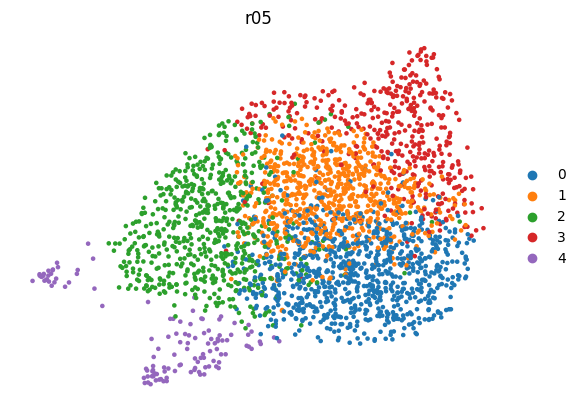

In [25]:
sc.pl.umap(adata_genes,color='r05',frameon=False)

In [ ]:
adata_genes.write_h5ad(out_h5ad)
print(f"Saved -> {out_h5ad}")


## 10. Quick sanity checks

A few quick checks to confirm the output looks reasonable before moving on to
downstream analysis (e.g. clustering genes by embedding, comparing across sections, etc.).


In [19]:
print("Shape (genes x embedding dim):", adata_genes.shape)
print()
print("obs preview:")
adata_genes.obs.head()


Shape (genes x embedding dim): (2745, 384)

obs preview:


,gene_id,ensembl_id,n_cells,r05
ENSG00000127837,ENSG00000127837,ENSG00000127837,118,0
ENSG00000266967,ENSG00000266967,ENSG00000266967,13,0
ENSG00000183044,ENSG00000183044,ENSG00000183044,119,0
ENSG00000165029,ENSG00000165029,ENSG00000165029,52,0
ENSG00000167972,ENSG00000167972,ENSG00000167972,23,0


In [20]:
print("uns:", dict(adata_genes.uns))
print()
print("Embedding stats: mean =", adata_genes.X.mean(), " std =", adata_genes.X.std())


uns: {'section_id': 'K014', 'emb_type': 'neighborhood_gene_emb_average_per_data', 'n_cells_in_section': 1630, 'pca': {'params': {'zero_center': True, 'use_highly_variable': False, 'mask_var': None}, 'variance': array([6.13150193, 3.71535528, 2.82164261, 2.19282437, 1.90744407,
       1.62918508, 1.52146417, 1.42231136, 1.34815456, 1.32299426,
       1.31748459, 1.29875273, 1.25899684, 1.21693244, 1.20291702,
       1.18108338, 1.16833797, 1.14187354, 1.12898046, 1.11243926,
       1.09814627, 1.07214053, 1.0671951 , 1.05844174, 1.03256476,
       1.00996741, 1.00174241, 0.99309782, 0.98051886, 0.97360474,
       0.95000278, 0.9402138 , 0.93496286, 0.92922535, 0.9203677 ,
       0.91024245, 0.88903152, 0.87986282, 0.86889525, 0.85682229,
       0.84848136, 0.84232905, 0.83949432, 0.82887686, 0.81934134,
       0.81305632, 0.80451068, 0.79829065, 0.79234355, 0.78553608]), 'variance_ratio': array([0.04147129, 0.02512934, 0.01908458, 0.01483148, 0.01290127,
       0.01101923, 0.01029064, 0

## 11. Cleanup (optional)

Frees GPU memory — useful if you're about to run this notebook again for a different
section, or move on to another GPU-heavy task in the same kernel.


In [44]:
del torch_sub, output
gc.collect()
torch.cuda.empty_cache()
print("Done.")

Done.
